In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
# 데이터 분할 및 전처리
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import lightgbm as lgbm


In [11]:
# job, marital, contact, poutcome 은 순서가 없으니 전부 더미(0/1) 변수로 분리
df_dummies = pd.get_dummies(
    data[['job','marital','contact','poutcome']],
    drop_first=False,   
    prefix_sep='_'
)

edu_map = {'unknown':0, 'primary':1, 'secondary':2, 'tertiary':3}
data['education_ord'] = data['education'].map(edu_map)

df_num = data[['age','balance','campaign','pdays','previous','duration']]
df_bin = data[['housing','loan']].replace({'no':0,'yes':1})

y_col = data[['label']]

df_corr = pd.concat([df_num, df_bin, data[['education_ord']], df_dummies, y_col], axis=1)
corr = df_corr.corr()

# 2) 사이즈와 폰트 스케일 조정
plt.figure(figsize=(20, 16))        
sns.set(font_scale=0.8)             

# 3) heatmap 그리기
ax = sns.heatmap(
    corr,
    cmap='coolwarm',                
    annot=True,                     
    fmt='.2f',                      
    linewidths=0.5,                 
    cbar_kws={"shrink": .5}         
)

# 4) 축 레이블 회전 및 정렬
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=90,                    
    ha='center'                    
)
ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,                     
    va='center'                     
)

plt.tight_layout()                  
plt.show()


NameError: name 'data' is not defined

In [12]:
from sklearn.base import BaseEstimator, TransformerMixin


In [13]:
class DataFrameSelector(BaseEstimator, TransformerMixin):
    def __init__(self, attribute_names):
        self.attribute_names = attribute_names
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.attribute_names]

In [14]:
# 사용자 정의 CategoricalEncoder
class CategoricalEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, encoding='onehot-dense', categories='auto', dtype=np.float64, handle_unknown='ignore'):
        self.encoding = encoding
        self.categories = categories
        self.dtype = dtype
        self.handle_unknown = handle_unknown

    def fit(self, X, y=None):
        from sklearn.utils import check_array
        from sklearn.preprocessing import LabelEncoder
        X = check_array(X, dtype=object, accept_sparse='csc', copy=True)
        n_samples, n_features = X.shape
        self._label_encoders_ = [LabelEncoder() for _ in range(n_features)]
        for i in range(n_features):
            Xi = X[:, i]
            le = self._label_encoders_[i]
            if self.categories == 'auto':
                le.fit(Xi)
            else:
                le.classes_ = np.array(sorted(self.categories[i]))
        self.categories_ = [le.classes_ for le in self._label_encoders_]
        return self

    def transform(self, X):
        from sklearn.utils import check_array
        X = check_array(X, dtype=object, accept_sparse='csc', copy=True)
        n_samples, n_features = X.shape
        X_int = np.zeros_like(X, dtype=int)
        mask = np.ones_like(X, dtype=bool)
        for i in range(n_features):
            valid = np.in1d(X[:, i], self.categories_[i])
            if not valid.all():
                if self.handle_unknown == 'error':
                    raise ValueError(f"Unknown categories in column {i}")
                X[~valid, i] = self.categories_[i][0]
            X_int[:, i] = self._label_encoders_[i].transform(X[:, i])
            mask[:, i] = valid
        if self.encoding == 'ordinal':
            return X_int.astype(self.dtype)
        # one-hot
        n_values = [cats.size for cats in self.categories_]
        indices = np.cumsum([0] + n_values)
        row_idx = np.repeat(np.arange(n_samples), n_features)[mask.ravel()]
        col_idx = (X_int + indices[:-1]).ravel()[mask.ravel()]
        data = np.ones_like(col_idx, dtype=self.dtype)
        mat = sparse.csr_matrix((data, (row_idx, col_idx)), shape=(n_samples, indices[-1]))
        if self.encoding == 'onehot-dense':
            return mat.toarray()
        return mat

# DataFrameSelector 정의
class DataFrameSelector(BaseEstimator, TransformerMixin):
    def __init__(self, columns): self.columns = columns
    def fit(self, X, y=None): return self
    def transform(self, X): return X[self.columns].values

In [15]:
num_cols = ["age", "balance", "day", "campaign", "pdays", "previous","duration"]
cat_cols = ["job", "education", "marital", "default", "housing", "loan", "contact", "month", "poutcome"]

# pipeline
def build_preprocessor(num_cols, cat_cols):
    num_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler())
    ])
    cat_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
        ('encode', CategoricalEncoder(encoding='onehot-dense',
                                      handle_unknown='ignore'))
    ])
    return ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, cat_cols)
    ])

preprocessor = build_preprocessor(num_cols, cat_cols)

### 검증데이터 분리

In [16]:
# 데이터 로드 
train_df = pd.read_csv('train.csv')
X = train_df[num_cols + cat_cols]
y = train_df['label']

#전처리 & 학습/검증 분리
X_trans = preprocessor.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(
    X_trans, y, test_size=0.2, random_state=42, stratify=y
)

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_47476/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_47476/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_47476/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_47476/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_47476/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xj

In [26]:
test_df = pd.read_csv('test.csv')
X_test_col = test_df[num_cols + cat_cols]      # 같은 feature 컬럼만
X_test = preprocessor.transform(X_test_col)  # **transform만!**


/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_47476/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_47476/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_47476/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_47476/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_47476/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xj

#### 3.2 초기 모델 정의 및 학습

In [18]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

base_model = GradientBoostingClassifier(random_state=42)
base_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [19]:
# Feature Names 생성
num_features = num_cols.copy()
cat_pipe = preprocessor.named_transformers_['cat']
encoder  = cat_pipe.named_steps['encode']
categories = encoder.categories_

cat_features = []
for col, cats in zip(cat_cols, categories):
    for cat in cats:
        cat_features.append(f"{col}_{cat}")

feature_names = num_features + cat_features

#### 3.3 변수 중요도 분석

In [21]:
# 10) Feature Importances 추출 & 정리
importances = base_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

print(importance_df.to_string(index=False))

            Feature  Importance
           duration    0.440586
   poutcome_success    0.188554
                age    0.042334
    contact_unknown    0.041394
              pdays    0.036082
          month_mar    0.031386
         housing_no    0.027935
          month_oct    0.024814
          month_apr    0.022725
        housing_yes    0.020901
          month_jun    0.020816
                day    0.017229
            balance    0.011130
          month_sep    0.009848
          month_feb    0.009069
          month_nov    0.009053
           campaign    0.008281
           previous    0.006185
          month_dec    0.005345
   contact_cellular    0.005111
          month_jan    0.003449
    marital_married    0.002961
          month_aug    0.002787
        job_student    0.002757
 education_tertiary    0.002004
   poutcome_failure    0.000948
          month_jul    0.000918
   marital_divorced    0.000768
  education_primary    0.000765
            loan_no    0.000744
        

#### 3.4 변수 선택법

In [23]:
from sklearn.feature_selection import SequentialFeatureSelector

# 변수 선택 모델 정의
sfs = SequentialFeatureSelector(
    base_model,
    n_features_to_select='auto',
    direction='forward',
    scoring='f1',
    cv=5,
    n_jobs=-1
)
# 변수 선택 모델 학습하기
sfs.fit(X_train, y_train)

SequentialFeatureSelector(estimator=GradientBoostingClassifier(random_state=42),
                          n_jobs=-1, scoring='f1')

In [24]:
mask = sfs.get_support()  
selected_features = [name for name, keep in zip(feature_names, mask) if keep]
print("선택된 변수:", selected_features)

선택된 변수: ['age', 'balance', 'pdays', 'duration', 'job_self-employed', 'job_technician', 'job_unemployed', 'education_primary', 'marital_married', 'marital_single', 'default_no', 'default_yes', 'housing_no', 'housing_yes', 'loan_no', 'loan_yes', 'contact_cellular', 'month_apr', 'month_aug', 'month_jan', 'month_mar', 'month_sep', 'poutcome_failure', 'poutcome_success', 'poutcome_unknown']


In [33]:
#선택된 변수: ['age', 'balance', 'pdays', 'duration', 'job_self-employed', 'job_technician', 'job_unemployed', 'education_primary', 'marital_married', 'marital_single', 'default_no', 'default_yes', 'housing_no', 'housing_yes', 'loan_no', 'loan_yes', 'contact_cellular', 'month_apr', 'month_aug', 'month_jan', 'month_mar', 'month_sep', 'poutcome_failure', 'poutcome_success', 'poutcome_unknown']

In [27]:
# NumPy 배열(X_train, X_val, X_test)을 DataFrame으로 변환
df_retrn_x_df = pd.DataFrame(X_train, columns=feature_names)
df_val_x_df   = pd.DataFrame(X_val,   columns=feature_names)
df_tst_x_df   = pd.DataFrame(X_test,  columns=feature_names)

# 선택된 변수만 골라내기
df_retrn_x_selected = df_retrn_x_df[selected_features]
df_val_x_selected   = df_val_x_df[selected_features]
df_tst_x_selected   = df_tst_x_df[selected_features]


In [30]:
base_model.fit(df_retrn_x_selected , y_train)
val_pred = base_model.predict(df_val_x_selected )

### 하이퍼파라미터 튜닝 (GBM - Random)

In [33]:
param_dist = {
    'n_estimators':       np.arange(100,1000,100),
    'learning_rate':      np.arange(0.1,0.9,0.05),
    'max_depth':          [3, 4, 5, 6],
    'min_samples_split':  np.arange(1,8),
    'min_samples_leaf':   [1, 2, 5, 10],
    'subsample':          [0.6, 0.7, 0.8, 0.9, 1.0],
    'max_features':       ['sqrt', 'log2', None]
}



In [34]:
# 3) GradientBoostingClassifier와 RandomizedSearchCV 설정
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, f1_score

random_search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_dist,
    n_iter=50,                    
    scoring=make_scorer(f1_score),
    cv=5,                         
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [35]:
# y 값 가중치 주기
from sklearn.utils.class_weight import compute_sample_weight

sample_weight = compute_sample_weight('balanced', y_train)


In [37]:
random_search.fit(df_retrn_x_selected, y_train,sample_weight=sample_weight)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
30 fits failed out of a total of 250.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
30 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constra

RandomizedSearchCV(cv=5, estimator=GradientBoostingClassifier(random_state=42),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'learning_rate': array([0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55, 0.6 ,
       0.65, 0.7 , 0.75, 0.8 , 0.85]),
                                        'max_depth': [3, 4, 5, 6],
                                        'max_features': ['sqrt', 'log2', None],
                                        'min_samples_leaf': [1, 2, 5, 10],
                                        'min_samples_split': array([1, 2, 3, 4, 5, 6, 7]),
                                        'n_estimators': array([100, 200, 300, 400, 500, 600, 700, 800, 900]),
                                        'subsample': [0.6, 0.7, 0.8, 0.9, 1.0]},
                   random_state=42,
                   scoring=make_scorer(f1_score, response_method='predict'),
                   verbose=1)

In [38]:
best_params = random_search.best_params_
best_gbm = random_search.best_estimator_

In [41]:
print(best_params)

{'subsample': 0.6, 'n_estimators': np.int64(200), 'min_samples_split': np.int64(4), 'min_samples_leaf': 5, 'max_features': None, 'max_depth': 5, 'learning_rate': np.float64(0.20000000000000004)}


In [ ]:
#{'subsample': 0.6, 'n_estimators': np.int64(200), 'min_samples_split': np.int64(4), 'min_samples_leaf': 5, 'max_features': None, 'max_depth': 5, 'learning_rate': np.float64(0.20000000000000004)}

In [42]:
from sklearn.metrics import precision_recall_curve
# 모델 평가 지표
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# 데이터 시각화
import seaborn as sns

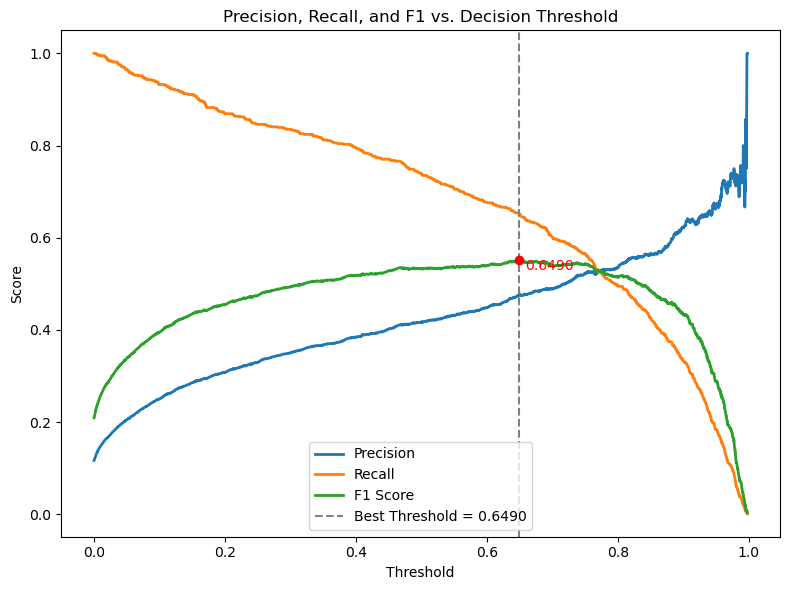

최적의 threshold: 0.6490, F1 = 0.5511


In [50]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve

# 1) 검증 확률 (best_gbm, df_val_x_selected, y_val 은 이미 정의된 상태)
probs_val = best_gbm.predict_proba(df_val_x_selected)[:, 1]

# 2) Precision / Recall / thresholds 계산
precision, recall, thresholds = precision_recall_curve(y_val, probs_val)

# 3) F1 Score 계산 (thresholds 길이와 맞추기 위해 마지막 precision/recall 제외)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)
f1_scores = f1_scores[:-1]  # thresholds 배열 길이와 맞추기

# 4) 최적 임계값 찾기
best_idx    = np.argmax(f1_scores)
best_thresh = thresholds[best_idx]
best_f1     = f1_scores[best_idx]

# 5) 그래프 그리기
plt.figure(figsize=(8,6))
plt.plot(thresholds, precision[:-1], label='Precision', linewidth=2)
plt.plot(thresholds, recall[:-1],    label='Recall',    linewidth=2)
plt.plot(thresholds, f1_scores,      label='F1 Score',   linewidth=2)
plt.axvline(best_thresh, color='gray', linestyle='--',
            label=f'Best Threshold = {best_thresh:.4f}')
plt.scatter(best_thresh, best_f1, color='red', zorder=5)
plt.text(best_thresh + 0.01, best_f1 - 0.02,
         f'{best_thresh:.4f}', color='red')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall, and F1 vs. Decision Threshold')
plt.legend()
plt.tight_layout()
plt.show()

print(f"최적의 threshold: {best_thresh:.4f}, F1 = {best_f1:.4f}")


### 5. 모델 평가

In [51]:
# threshold 설정
thres=0.6490

In [54]:
# 훈련 데이터에 대한 성능 평가
y_retrn_pred_proba = best_gbm.predict_proba(df_retrn_x_selected)[:, 1]
y_retrn_pred_label = (y_retrn_pred_proba > thres).astype(int)

print(f"훈련 데이터 Accuracy: {accuracy_score(y_train, y_retrn_pred_label)}")
print(f"훈련 데이터 Precision: {precision_score(y_train, y_retrn_pred_label)}")
print(f"훈련 데이터 Recall: {recall_score(y_train, y_retrn_pred_label)}")
print(f"훈련 데이터 F1 Score: {f1_score(y_train, y_retrn_pred_label)}")

훈련 데이터 Accuracy: 0.9287040328632934
훈련 데이터 Precision: 0.6430868167202572
훈련 데이터 Recall: 0.8777852802160703
훈련 데이터 F1 Score: 0.742326909350464


검증 데이터로 성능 평가

In [56]:
# 검증 데이터에 대한 성능 평가
y_val_pred_proba = best_gbm.predict_proba(df_val_x_selected)[:, 1]
y_val_pred_label = (y_val_pred_proba > thres).astype(int)

print(f"검증 데이터 Accuracy: {accuracy_score(y_val, y_val_pred_label)}")
print(f"검증 데이터 Precision: {precision_score(y_val, y_val_pred_label)}")
print(f"검증 데이터 Recall: {recall_score(y_val, y_val_pred_label)}")
print(f"검증 데이터 F1 Score: {f1_score(y_val, y_val_pred_label)}")

검증 데이터 Accuracy: 0.8756714060031595
검증 데이터 Precision: 0.4768015794669299
검증 데이터 Recall: 0.6527027027027027
검증 데이터 F1 Score: 0.5510553337136338


In [ ]:
import shap
import matplotlib.pyplot as plt

# 1) TreeExplainer 생성
#    best_model: 이미 학습된 LGBMClassifier 혹은 GradientBoostingClassifier
explainer = shap.TreeExplainer(base_model)

# 2) SHAP 값 계산
#    X_train: 전처리된 훈련용 특성 행렬 (NumPy array 또는 DataFrame)
shap_values = explainer.shap_values(X_train)

# 3) 글로벌 중요도 (bar plot)
shap.summary_plot(
    shap_values, 
    X_train, 
    feature_names=feature_names, 
    plot_type="bar"
)

# 4) 변수별 분포 (beeswarm plot)
shap.summary_plot(
    shap_values, 
    X_train, 
    feature_names=feature_names
)
